## Computing Cost
Here, cost is a measure how well our model is predicting the target price of the house.

The equation for cost with one variable is:
  $$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2 \tag{1}$$

where
  $$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{2}$$
  
- $f_{w,b}(x^{(i)})$ is our prediction for example $i$ using parameters $w,b$.  
- $(f_{w,b}(x^{(i)}) -y^{(i)})^2$ is the squared difference between the target value and the prediction.   


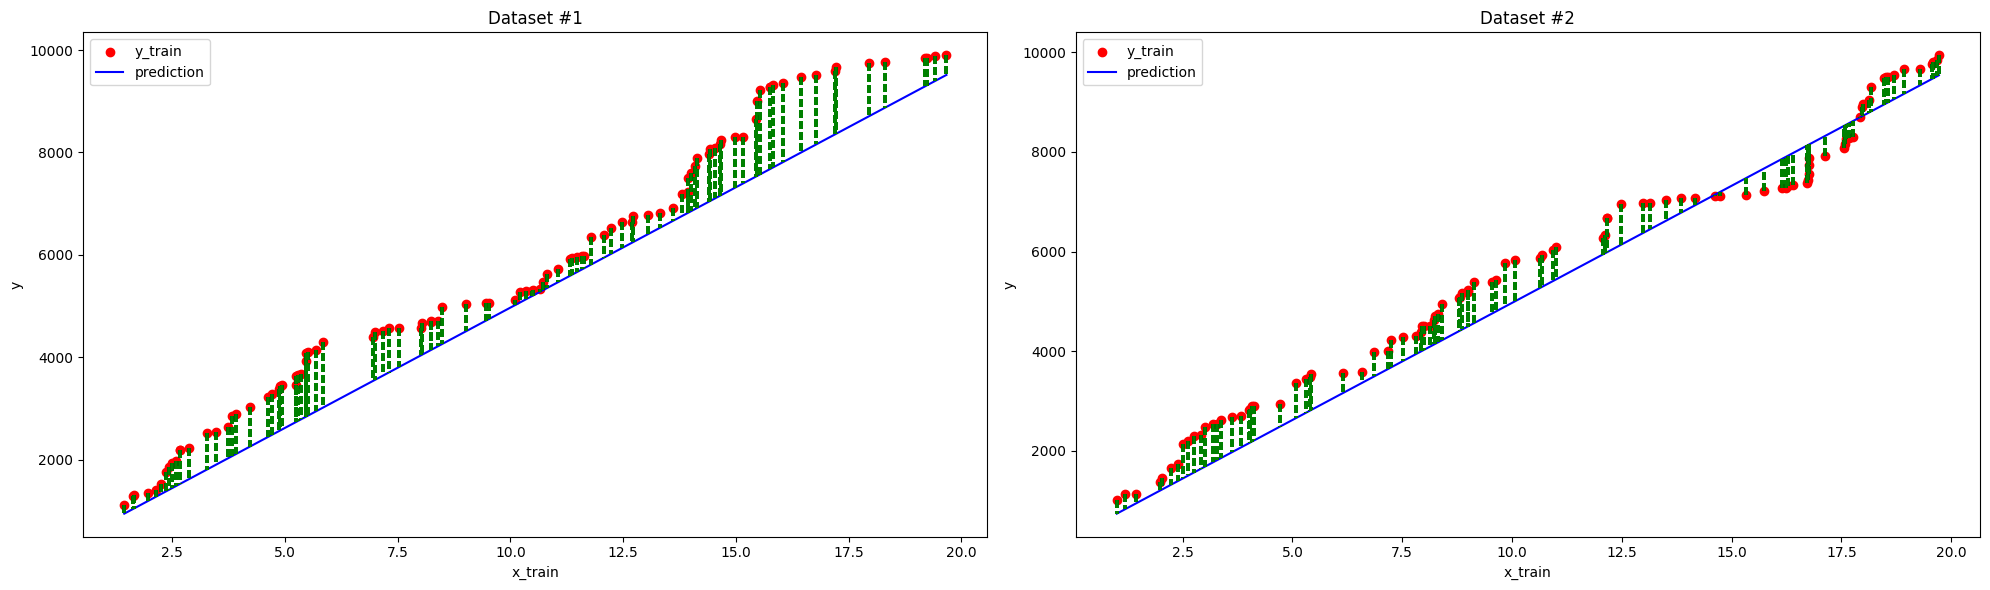

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import random as random

def compute_model_prediction(w, b, x_train):
    m = x_train.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x_train[i] + b
    return f_wb

def cost_function(w, b, x_train, y_train,f_wb):
    m = x_train.shape[0]
    cost_sum=0
    for i in range(m):
        difference=f_wb[i] - y_train[i]
        squared_difference=np.square(difference)
        cost_sum=cost_sum+squared_difference
    lt=cost_sum/(2*m)
    return difference,lt

m = 100
w = 470
b = 270

fig,axes = plt.subplots(1,2,figsize=(20, 6))

for idx in range(2):
    x_train = np.zeros(m)
    y_train = np.zeros(m)

    for j in range(m):
        x_train[j] = round(random.uniform(1, 20), 3)
        y_train[j] = round(random.uniform(1000, 10000), 2)

    x_train = np.sort(x_train)
    y_train = np.sort(y_train)

    prediction = compute_model_prediction(w, b, x_train)
    difference,lt=cost_function(w, b, x_train, y_train,prediction)

    axes[idx].scatter(x_train, y_train, color="red", label="y_train")
    axes[idx].plot(x_train, prediction, color="blue", label="prediction")

    for i in range(m):
      axes[idx].plot(
                     [x_train,x_train],
                     [y_train,prediction],
                     linestyle="dashed", color="green")
    axes[idx].set_title(f"Dataset #{idx + 1}")
    axes[idx].set_xlabel("x_train")
    axes[idx].set_ylabel("y")
    axes[idx].legend()

plt.tight_layout()
plt.show()


